In [1]:
!pip install textblob pandas matplotlib seaborn


In [2]:
import pandas as pd
from textblob import TextBlob
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create a dataset of book reviews
data = {
    'Review': [
        "This book was absolutely amazing! I couldn't put it down. Best purchase ever.",
        "Terrible. The plot was boring and the characters were flat. Waste of money.",
        "It was okay. Not the best book I've read, but it passed the time.",
        "I loved every page of this. The author is a genius!",
        "The ending was so disappointing. I feel like I wasted my weekend.",
        "Great quality and fast shipping. The story was decent.",
        "A masterpiece. I will definitely read it again.",
        "Do not buy this. The pages were missing and the story made no sense.",
        "An average read. Nothing special, but nothing terrible either.",
        "Beautifully written. It made me cry!"
    ]
}

df = pd.DataFrame(data)

# 2. Define a function to get sentiment polarity
def get_sentiment(text):
    analysis = TextBlob(text)
    # Polarity ranges from -1 (negative) to 1 (positive)
    polarity = analysis.sentiment.polarity

    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

# 3. Apply the function to our dataset
df['Polarity_Score'] = df['Review'].apply(lambda x: TextBlob(x).sentiment.polarity)
df['Sentiment'] = df['Review'].apply(get_sentiment)

# 4. Show the results
print("--- Sentiment Analysis Results ---")
print(df[['Review', 'Sentiment', 'Polarity_Score']].head(10))

--- Sentiment Analysis Results ---
                                              Review Sentiment  Polarity_Score
0  This book was absolutely amazing! I couldn't p...  Positive        0.531481
1  Terrible. The plot was boring and the characte...  Negative       -0.556250
2  It was okay. Not the best book I've read, but ...  Positive        0.750000
3  I loved every page of this. The author is a ge...  Positive        0.875000
4  The ending was so disappointing. I feel like I...  Negative       -0.400000
5  Great quality and fast shipping. The story was...  Positive        0.388889
6    A masterpiece. I will definitely read it again.   Neutral        0.000000
7  Do not buy this. The pages were missing and th...  Negative       -0.200000
8  An average read. Nothing special, but nothing ...  Negative       -0.264286
9               Beautifully written. It made me cry!  Positive        1.000000


/tmp/ipykernel_2672/727739170.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Sentiment', palette={'Positive': 'green', 'Neutral': 'gray', 'Negative': 'red'}, order=['Positive', 'Neutral', 'Negative'])


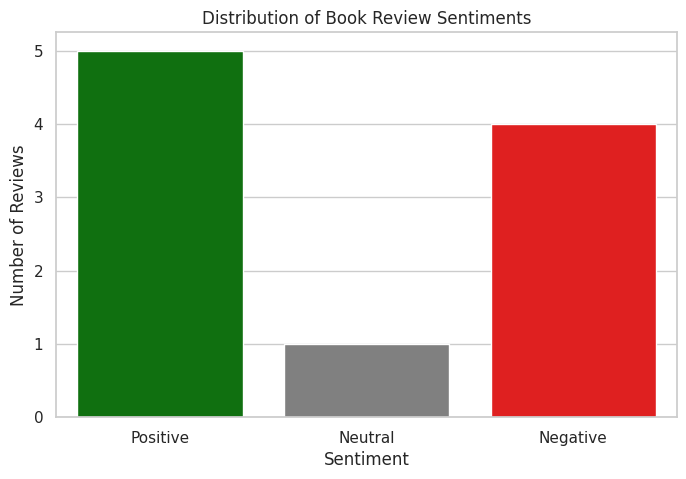

In [3]:
# Set the visual style
sns.set_theme(style="whitegrid")

# Create a bar chart of sentiment counts
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Sentiment', palette={'Positive': 'green', 'Neutral': 'gray', 'Negative': 'red'}, order=['Positive', 'Neutral', 'Negative'])

plt.title('Distribution of Book Review Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

# Save the chart for GitHub
plt.savefig('sentiment_visualization.png')

plt.show()